# 03 · Feature Engineering

En este proyecto no se entrena ningún modelo: un LLM recibe el tuit y devuelve una etiqueta. Aun así hay trabajo de ingeniería de características, y este notebook lo documenta.

**Qué significa aquí "feature engineering"**

1. **Qué ve el LLM**: cómo se normaliza el tuit antes del prompt y qué información no se le da (la variedad).
2. **Catálogo de 24 características** lingüísticas y de superficie, calculadas con reglas. Sirven para entender el corpus, contrastar al agente de Percepción y armar líneas base.
3. **Representaciones TF-IDF**, usadas **solo como piso de comparación**.
4. **Control de atajos y de robustez**: qué características delatan el país y cuáles resisten las perturbaciones del texto.

**Higiene.** Todo lo que se ajusta (vectorizadores, escalado, modelos de referencia) se ajusta solo con *train* y se mide solo en *dev*. No se toca ninguna partición de prueba. Los modelos de regresión logística de este notebook son referencias, no el experimento.

**Resumen en seis líneas**

- El **léxico** es lo único indispensable del catálogo: quitarlo baja el Macro-F1 en 0,075, quitar cualquier otro grupo no cambia nada distinguible. Solo con las 3 características de léxico se llega a 0,48, frente a 0,51 con las 24.
- **TF-IDF de palabras supera a las 24 características** (diferencia de 0,047, IC 0,025 a 0,068). Combinarlas con las palabras no mejora.
- **No se distingue** entre TF-IDF de palabras, de caracteres y su combinación (los intervalos de la diferencia incluyen 0).
- Las **banderas del agente de Percepción**, como reglas aisladas, dicen poco salvo la doble negación.
- Las características **conversacionales** delatan el país más que el sentimiento.
- Las características con **mayúsculas** son frágiles: ponerlas en mayúsculas baja 0,084 un modelo numérico, mientras que TF-IDF no cambia.

**Índice:** 1 Qué ve el LLM · 2 Catálogo · 3 Distribución · 4 Señal por etiqueta · 5 Redundancia · 6 Atajos por país · 7 Comparar representaciones · 8 Qué aporta cada grupo · 9 Estabilidad frente a perturbaciones · 10 Palabras por clase · 11 Conclusiones.

### Dónde encaja cada pieza en el sistema

In [1]:
import pandas as pd
pd.set_option("display.max_colwidth", 120)
pd.DataFrame([
    ("Normalización del texto", "Pipeline, antes de todos los agentes", "Prepara el prompt: anonimiza menciones y enlaces, conserva el tono, no pasa la variedad."),
    ("Fenómeno (4)", "Agente de Percepción", "Las reglas son el piso con el que se compara lo que el agente detecte: diminutivo, doble negación, code-switching, risa."),
    ("Léxico (3)", "Línea base de referencia", "Mide cuánta señal da una lista corta. No entra al prompt de ningún agente."),
    ("Estructural, expresividad, conversacional (17)", "Análisis y control", "Describen el corpus, permiten revisar atajos por país y alimentan los modelos de referencia."),
    ("TF-IDF de palabras y de caracteres", "Línea base de referencia", "Piso que el monoagente y el multiagente deben superar. No forma parte del experimento."),
], columns=["componente", "dónde se usa", "para qué"])

,componente,dónde se usa,para qué
0,Normalización del texto,"Pipeline, antes de todos los agentes","Prepara el prompt: anonimiza menciones y enlaces, conserva el tono, no pasa la variedad."
1,Fenómeno (4),Agente de Percepción,"Las reglas son el piso con el que se compara lo que el agente detecte: diminutivo, doble negación, code-switching, r..."
2,Léxico (3),Línea base de referencia,Mide cuánta señal da una lista corta. No entra al prompt de ningún agente.
3,"Estructural, expresividad, conversacional (17)",Análisis y control,"Describen el corpus, permiten revisar atajos por país y alimentan los modelos de referencia."
4,TF-IDF de palabras y de caracteres,Línea base de referencia,Piso que el monoagente y el multiagente deben superar. No forma parte del experimento.


In [2]:
import sys
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

RAIZ = Path("..").resolve()
sys.path.insert(0, str(RAIZ / "scripts" / "features"))
sys.path.insert(0, str(RAIZ / "scripts" / "eda"))
import feature_utils as F
import eda_utils as E
import run_features as RF

pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 70)
FIG = RAIZ / "docs" / "features" / "figuras"

corpus = E.cargar_corpus(RAIZ / "data")
M = F.construir_matriz(corpus)
print(f"{len(corpus):,} tuits · {M.shape[1]} características")

7,267 tuits · 24 características


## 1. Qué ve el LLM

Antes de armar cualquier característica, hay que decidir qué texto entra al prompt. La función `normalizar_para_llm` hace lo mínimo y deja intactas las señales que el modelo debe ver.

In [3]:
ejemplos = [
    "@juan  mira esto https://t.co/xx  JAJAJA qué bueeeno!!! 😂",
    "No me gusta nada...   @maria no vuelvo más",
    "Qué lindo día, gatitos por todos lados :)",
]
pd.DataFrame({"original (inventado)": ejemplos, "lo que ve el LLM": [F.normalizar_para_llm(t) for t in ejemplos]})

,original (inventado),lo que ve el LLM
0,@juan mira esto https://t.co/xx JAJAJA qué bueeeno!!! 😂,@USUARIO mira esto URL JAJAJA qué bueeeno!!! 😂
1,No me gusta nada... @maria no vuelvo más,No me gusta nada... @USUARIO no vuelvo más
2,"Qué lindo día, gatitos por todos lados :)","Qué lindo día, gatitos por todos lados :)"


**Decisiones.**
- Las **@menciones** pasan a `@USUARIO` y los **enlaces** a `URL`: privacidad y menos ruido, pero se conserva el hecho de que el tuit es una respuesta.
- **No se toca** mayúsculas, puntuación, alargamientos, emojis ni tildes: son señales de tono que el LLM debe ver.
- **No se le da la variedad.** El sistema no debe saber de qué país es el tuit. La variedad solo se usa para reportar resultados por país.

## 2. Catálogo de características

Cada característica tiene un grupo, una definición y una razón para incluirla. Todas son reglas simples y transparentes.

In [4]:
cat = F.catalogo_features()
display(cat.groupby("grupo").size().rename("n").to_frame().T)
cat[["feature", "grupo", "tipo", "definicion"]]

grupo,conversacional,estructural,expresividad,fenomeno,lexico
n,4,6,7,4,3


,feature,grupo,tipo,definicion
0,n_caracteres,estructural,conteo,Longitud del tuit en caracteres.
1,n_palabras,estructural,conteo,Número de palabras (secuencias de letras).
2,long_media_palabra,estructural,razón,Caracteres de letras por palabra.
3,n_oraciones,estructural,conteo,Segmentos terminados en . ! ? (mínimo 1).
4,ratio_mayusculas,estructural,razón,Fracción de letras en mayúscula.
5,n_digitos,estructural,conteo,Cantidad de dígitos.
6,n_exclamaciones,expresividad,conteo,Signos ! en el tuit.
7,n_interrogaciones,expresividad,conteo,Signos ? en el tuit.
8,n_puntos_suspensivos,expresividad,conteo,Secuencias de 3 o más puntos.
9,n_alargamientos,expresividad,conteo,Letras repetidas 3 o más veces (holaaa).


**Lectura.** Son 24 características en cinco grupos: *estructural* (6), *expresividad* (7), *conversacional* (4), *fenómeno* (4, las reglas del agente de Percepción) y *léxico* (3). Las de fenómeno son las mismas heurísticas del script de auditoría, con una corrección de nombre: lo que antes se llamaba "sarcasmo" aquí es `n_risas`, porque solo detecta risas. El **léxico** (`n_lex_positivo`, `n_lex_negativo`) es una lista corta y propia, sin validar: se incluye para medir cuánta señal da una lista pequeña, no como léxico de referencia.

## 3. Cómo se distribuyen

In [5]:
est = M.describe().T[["mean", "50%", "max"]].round(2)
est["% tuits con al menos 1"] = ((M > 0).mean() * 100).round(1)
est

,mean,50%,max,% tuits con al menos 1
n_caracteres,89.90,92.00,146.00,100.0
n_palabras,16.06,16.00,35.00,100.0
long_media_palabra,4.58,4.42,14.14,100.0
n_oraciones,1.57,1.00,9.00,100.0
ratio_mayusculas,0.05,0.03,0.84,88.6
n_digitos,0.58,0.00,24.00,21.5
n_exclamaciones,0.31,0.00,18.00,14.9
n_interrogaciones,0.11,0.00,8.00,7.7
n_puntos_suspensivos,0.11,0.00,5.00,9.2
n_alargamientos,0.06,0.00,5.00,4.9


**Lectura.** Casi todas las características son conteos pequeños y muy dispersos. `n_emojis` (0,2% de los tuits), `n_emoticonos` (0,1%), `tiene_url` (0,6%) y `n_marcadores_ingles` (0,9%) casi no aparecen, así que no pueden aportar mucho al sentimiento ni al análisis por país. Lo que sí está presente de forma amplia es la longitud (100% de los tuits), las mayúsculas (89%), las menciones (49%) y la negación (34%).

## 4. ¿Qué características distinguen las etiquetas?

Se mide cuánto cambia cada característica entre NEG, NEU y POS con una prueba de Kruskal-Wallis. Se reporta el tamaño de efecto (epsilon cuadrado, de 0 a 1), porque con 7.267 tuits casi todo sale "significativo".

In [6]:
aso = F.asociacion_univariada(M, corpus["etiqueta"], corpus["variedad"])
aso[["feature", "grupo", "efecto_etiqueta", "efecto_variedad", "mas_ligada_a"]].head(12)

,feature,grupo,efecto_etiqueta,efecto_variedad,mas_ligada_a
0,n_lex_positivo,lexico,0.13856,0.00646,etiqueta
1,n_lex_negativo,lexico,0.06411,0.00419,etiqueta
2,n_negaciones,fenomeno,0.04686,0.00172,etiqueta
3,n_exclamaciones,expresividad,0.04632,0.01166,etiqueta
4,n_menciones,conversacional,0.02702,0.04117,variedad
5,long_media_palabra,estructural,0.02696,0.00786,etiqueta
6,empieza_con_mencion,conversacional,0.02006,0.03488,variedad
7,ratio_mayusculas,estructural,0.01423,0.00333,etiqueta
8,n_intensificadores,lexico,0.01265,0.00424,etiqueta
9,n_oraciones,estructural,0.01192,0.00131,etiqueta


In [7]:
F.medias_por_etiqueta(M, corpus["etiqueta"]).loc[["n_lex_positivo", "n_lex_negativo", "n_negaciones", "n_exclamaciones", "n_interrogaciones", "n_menciones", "long_media_palabra"]]

etiqueta,NEG,NEU,POS
n_lex_positivo,0.161,0.253,0.677
n_lex_negativo,0.222,0.063,0.033
n_negaciones,0.618,0.445,0.254
n_exclamaciones,0.172,0.229,0.583
n_interrogaciones,0.111,0.136,0.066
n_menciones,0.503,0.711,0.759
long_media_palabra,4.410,4.608,4.765


**Lectura.**
- La señal más fuerte la da el **léxico mínimo**: `n_lex_positivo` (epsilon² = 0,139) y `n_lex_negativo` (0,064). Una lista de unas 30 palabras por lado (28 positivas y 29 negativas) ya separa bastante las clases.
- Le siguen la **negación** (0,047) y las **exclamaciones** (0,046). Los tuits POS tienen en promedio 0,58 exclamaciones frente a 0,17 en los NEG. Los NEG tienen más negaciones (0,62 frente a 0,25 en los POS).
- Las preguntas son más frecuentes en NEU que en POS, y el resto de las características de expresividad (emojis, emoticonos, mayúsculas) casi no distingue nada.
- La **longitud en caracteres no distingue** las etiquetas (epsilon² ≈ 0).

### Las banderas del agente de Percepción, una por una

Las cuatro reglas que imitan al agente de Percepción, ¿dicen algo del sentimiento por sí solas?

In [8]:
F.perfil_pistas(corpus, M)

,bandera,n,NEG_pct,NEU_pct,POS_pct
0,(todos los tuits),7267,39.1,32.0,28.9
1,diminutivo_afectivo,941,34.1,29.4,36.5
2,doble_negacion,671,55.1,30.3,14.6
3,code_switching,64,39.1,31.2,29.7
4,marcador_risa,458,29.9,36.9,33.2


**Lectura.** La **doble negación** es la bandera más informativa: entre los tuits que la activan, 55,1% son NEG frente a 39,1% en el total. El **diminutivo** inclina hacia POS (36,5% frente a 28,9%) y la **risa** aleja de NEG (29,9% frente a 39,1%), pero con efectos moderados. El **code-switching** (64 tuits) se comporta como el total y no aporta nada. Esto es importante para la hipótesis del proyecto: las banderas como reglas aisladas dicen poco, así que el valor del agente de Percepción tendría que estar en **interpretarlas en contexto**, por ejemplo distinguir una risa irónica de una alegre, algo que una regla no puede hacer.

## 5. Redundancia

In [9]:
F.correlaciones_altas(M)

,feature_a,feature_b,spearman_abs
0,n_caracteres,n_palabras,0.937
1,n_menciones,empieza_con_mencion,0.878


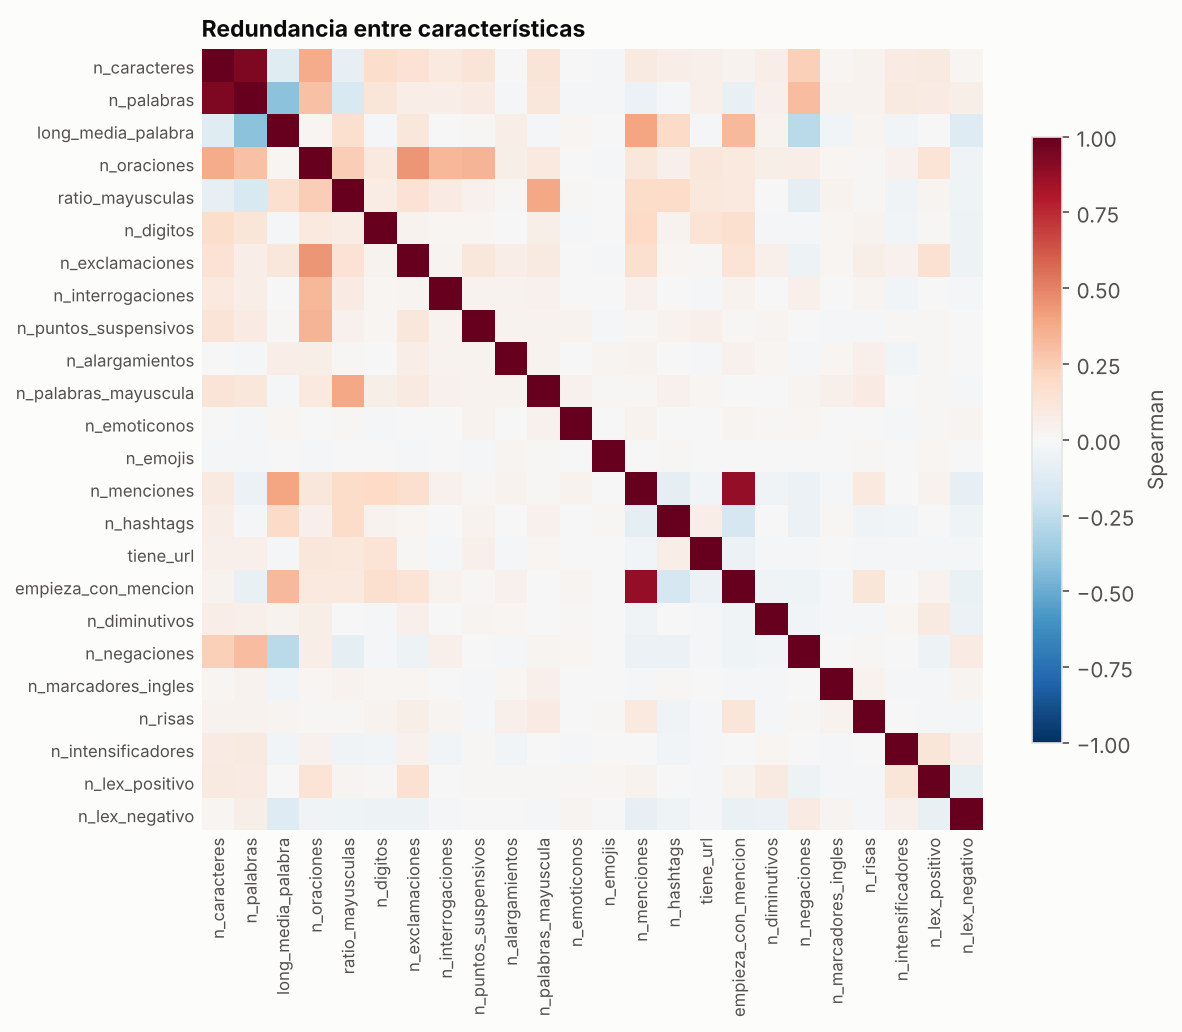

In [10]:
display(Image(filename=str(FIG / "fig04_correlaciones.png"))) if (FIG / "fig04_correlaciones.png").exists() else RF.fig_correlaciones(M, FIG / "fig04_correlaciones.png")

**Lectura.** Hay dos pares redundantes: `n_caracteres` con `n_palabras` (Spearman 0,94) y `n_menciones` con `empieza_con_mencion` (0,88). **Decisión:** para cualquier modelo de referencia con características numéricas conviene conservar una sola de cada par. Para el catálogo se dejan las dos porque cada una se explica por sí sola.

## 6. ¿Delatan el país en lugar del sentimiento?

Si una característica se relaciona más con la variedad que con la etiqueta, un sistema podría usarla como atajo. Aquí cada punto es una característica: arriba a la izquierda están las que hablan de sentimiento y abajo a la derecha las que hablan de país.

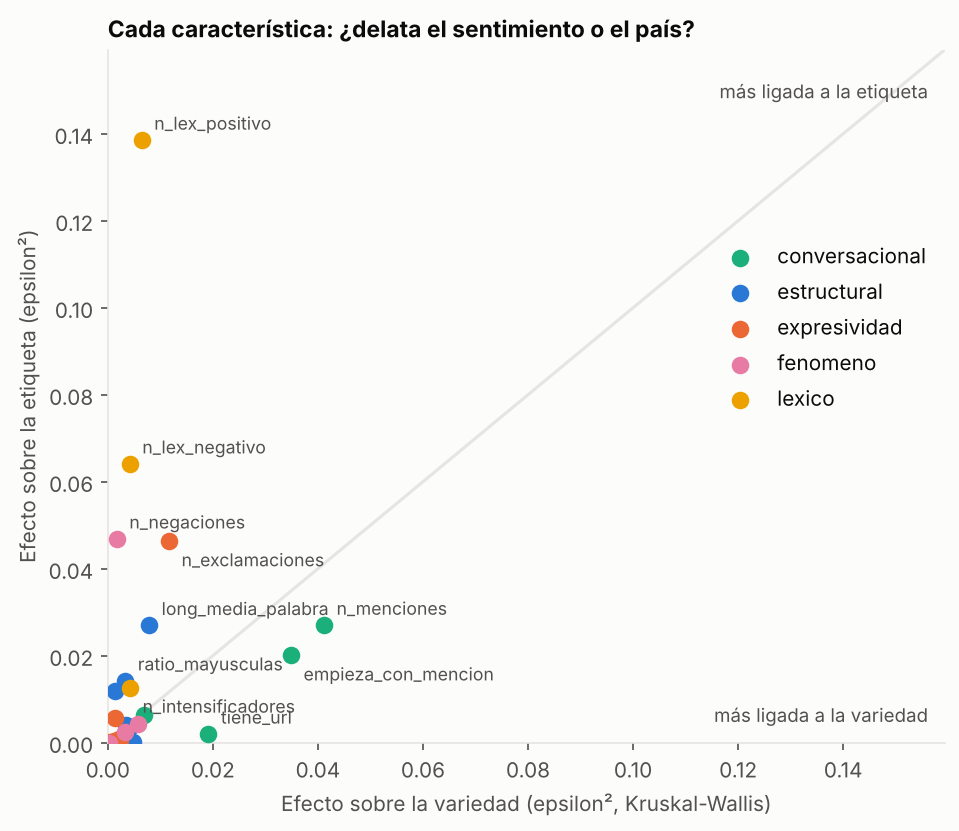

In [11]:
display(Image(filename=str(FIG / "fig02_efecto_etiqueta_vs_variedad.png")))

In [12]:
aso[aso.mas_ligada_a == "variedad"][["feature", "grupo", "efecto_etiqueta", "efecto_variedad"]].head(8)

,feature,grupo,efecto_etiqueta,efecto_variedad
4,n_menciones,conversacional,0.02702,0.04117
6,empieza_con_mencion,conversacional,0.02006,0.03488
10,n_hashtags,conversacional,0.00645,0.00692
12,n_diminutivos,fenomeno,0.00421,0.00568
14,n_palabras,estructural,0.00370,0.00427
15,n_risas,fenomeno,0.00241,0.00323
16,tiene_url,conversacional,0.00199,0.01915
17,n_puntos_suspensivos,expresividad,0.00082,0.00206


In [13]:
F.prediccion_de_variedad(corpus)

,representacion,n_dev,n_variedades,azar_aprox,accuracy_dev,macro_f1_dev,macro_f1_ic_inf,macro_f1_ic_sup
0,TF-IDF de palabras,2465,5,0.2,0.3858,0.3772,0.3609,0.3939
1,TF-IDF de caracteres,2465,5,0.2,0.3862,0.3758,0.3583,0.3930


**Lectura.**
- Las características **más ligadas al país que al sentimiento** son sobre todo las conversacionales: `n_menciones`, `empieza_con_mencion`, `tiene_url` y `n_hashtags`. Reflejan cómo se recolectó el corpus y el estilo de cada comunidad, no la polaridad.
- Solo con el texto, un clasificador de palabras adivina el país con un Macro-F1 de 0,38, frente a 0,20 al azar. Es decir, el texto **delata parcialmente el país** aunque no se lo digamos al LLM. Por eso la regla de no pasarle la variedad no es una garantía total de que no la use.
- **Decisión:** cualquier característica conversacional que se use en un modelo de referencia debe revisarse por país, y los resultados por país se reportan con el contexto temporal que ya vimos en el EDA.

## 7. Comparar representaciones (pisos de referencia)

Se compara qué representación del texto aporta más señal con regresión logística entrenada con *train* y medida en *dev*. **No es el experimento**: sirve para saber qué piso tiene que superar un sistema con LLM y si las características a mano aportan algo más allá de las palabras.

In [14]:
resumen, por_var = F.comparar_representaciones(corpus)
resumen

,representacion,n_dev,accuracy_dev,macro_f1_dev,macro_f1_ic_inf,macro_f1_ic_sup
0,0. Siempre la clase mayoritaria,2465,0.3895,0.1869,0.1801,0.1932
1,"1. Superficie (estructural, expresividad, conversacional)",2465,0.4381,0.4268,0.4072,0.4468
2,2. Superficie + fenómenos + léxico mínimo,2465,0.5120,0.5085,0.4883,0.5284
3,3. TF-IDF de palabras,2465,0.5615,0.5556,0.5363,0.5749
4,4. TF-IDF de caracteres,2465,0.5712,0.5678,0.5472,0.5880
5,5. TF-IDF palabras + caracteres,2465,0.5712,0.5660,0.5457,0.5852
6,6. TF-IDF palabras + todas las numéricas,2465,0.5611,0.5576,0.5375,0.5754


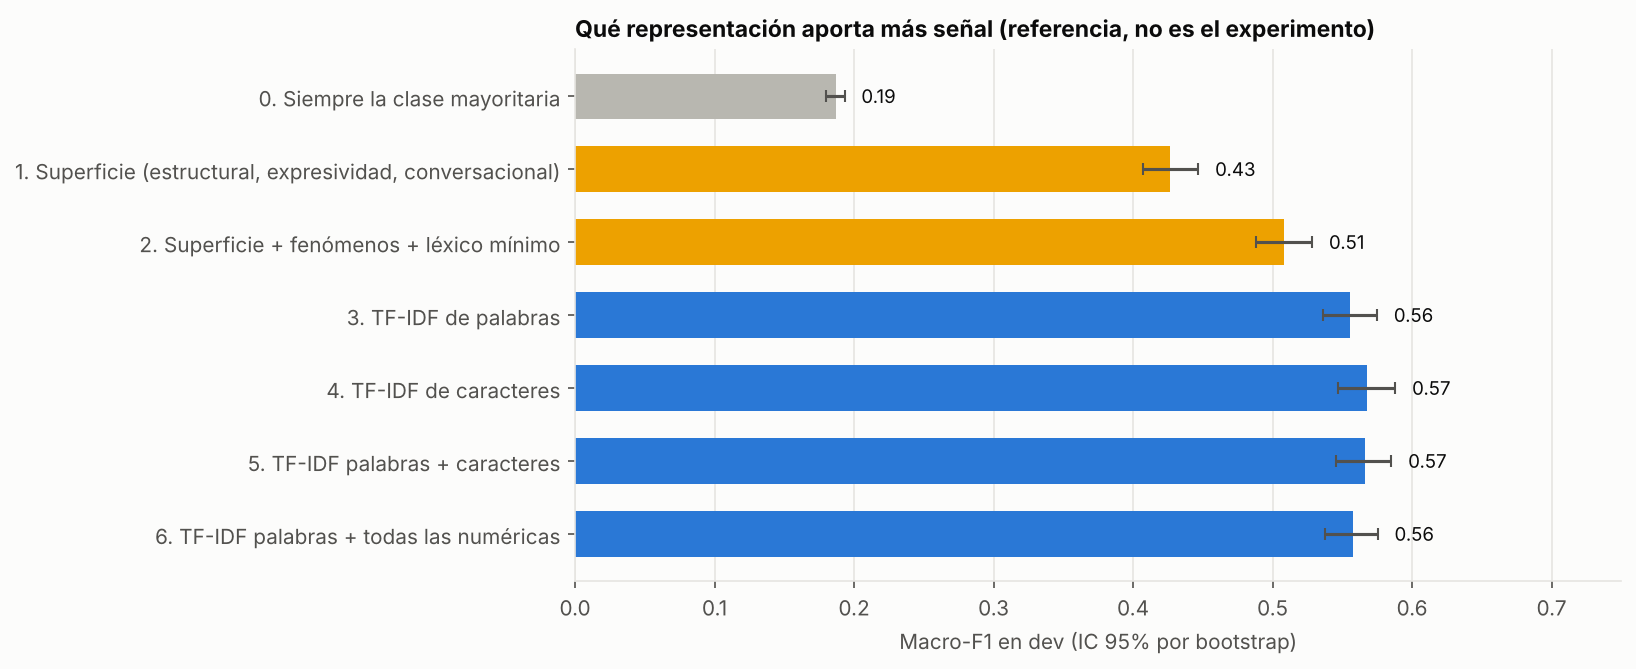

In [15]:
display(Image(filename=str(FIG / "fig01_comparacion_representaciones.png")))

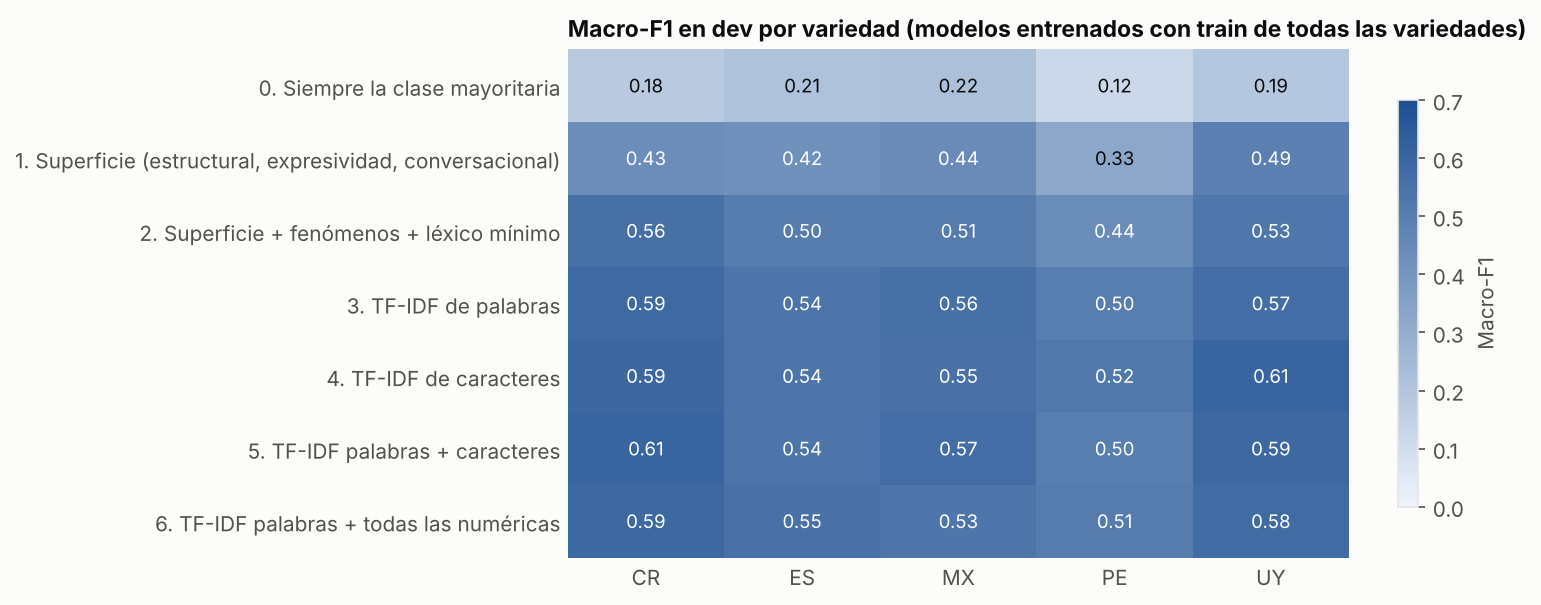

In [16]:
display(Image(filename=str(FIG / "fig03_macro_f1_por_variedad.png")))

### ¿Las diferencias entre representaciones son reales?

Comparar si dos intervalos se solapan no basta, porque los dos sistemas se miden sobre los mismos tuits. Aquí se usa un *bootstrap* pareado sobre la diferencia de Macro-F1 (2.000 remuestreos).

In [17]:
rep = F.Representaciones(corpus)
y_dev = rep.dev["etiqueta"].values
dif = F.diferencias_pareadas(y_dev, rep.predecir(), [("pal", "car"), ("pal", "pal+car"), ("pal", "pal+num"), ("car", "pal+car"), ("num", "pal"), ("num", "pal+num")])
dif[["A", "B", "dif_macro_f1_B_menos_A", "ic_inf", "ic_sup", "conclusion"]]

,A,B,dif_macro_f1_B_menos_A,ic_inf,ic_sup,conclusion
0,TF-IDF de palabras,TF-IDF de caracteres,0.0122,-0.0062,0.0319,no se distingue
1,TF-IDF de palabras,TF-IDF palabras + caracteres,0.0103,-0.0036,0.0245,no se distingue
2,TF-IDF de palabras,TF-IDF palabras + numéricas,0.0019,-0.0118,0.0162,no se distingue
3,TF-IDF de caracteres,TF-IDF palabras + caracteres,-0.0018,-0.0156,0.0128,no se distingue
4,Superficie + fenómenos + léxico (24 numéricas),TF-IDF de palabras,0.0472,0.0246,0.0683,B mejor
5,Superficie + fenómenos + léxico (24 numéricas),TF-IDF palabras + numéricas,0.0491,0.0309,0.0669,B mejor


**Lectura.**
- Siempre la clase mayoritaria: Macro-F1 de 0,19. Las características de **superficie solas** (longitud, puntuación, menciones) llegan a 0,43, así que parte de la señal está en la forma del texto.
- Con **fenómenos y léxico mínimo** se llega a 0,51: una lista corta de palabras vale mucho.
- **TF-IDF de palabras (0,56) supera a las 24 características** por 0,047 (IC 0,025 a 0,068), una diferencia que sí se distingue de cero.
- Entre **TF-IDF de palabras, de caracteres y su combinación no se distingue**: las diferencias son de 0,01 y sus intervalos incluyen 0. Agregar las características numéricas a las palabras tampoco mejora (diferencia de 0,002).
- Por país, **Perú** queda más abajo en casi todos los modelos (0,44 a 0,52), en línea con lo visto en el EDA sobre su proporción de neutrales.
- Conclusión práctica: un sistema con LLM debería compararse al menos contra el piso de **0,56 a 0,57**. Si un monoagente queda por debajo de TF-IDF, hay que reportarlo.

## 8. ¿Qué aporta cada grupo de características?

La asociación univariada de la sección 4 mira cada característica sola. Aquí se mira el efecto conjunto de dos formas: **quitar un grupo** del modelo de 24 características, o **usar un grupo solo**, y la **importancia por permutación**, que desordena una característica a la vez y mide cuánto cae el Macro-F1.

In [18]:
abl = F.ablacion_por_grupo(corpus)
abl

,configuracion,n_features,macro_f1_dev,cambio_vs_completo,ic_inf,ic_sup
0,Completo (5 grupos),24,0.5085,0.0000,0.0000,0.0000
1,Sin estructural,18,0.5067,-0.0017,-0.0099,0.0068
2,Sin expresividad,17,0.5174,0.0089,-0.0019,0.0201
3,Sin conversacional,20,0.5168,0.0083,-0.0054,0.0232
4,Sin fenomeno,20,0.5113,0.0028,-0.0080,0.0136
5,Sin lexico,21,0.4331,-0.0754,-0.0962,-0.0537
6,Solo estructural,6,0.3927,-0.1158,-0.1398,-0.0912
7,Solo expresividad,7,0.3542,-0.1543,-0.1783,-0.1285
8,Solo conversacional,4,0.3720,-0.1365,-0.1591,-0.1133
9,Solo fenomeno,4,0.3318,-0.1767,-0.2005,-0.1543


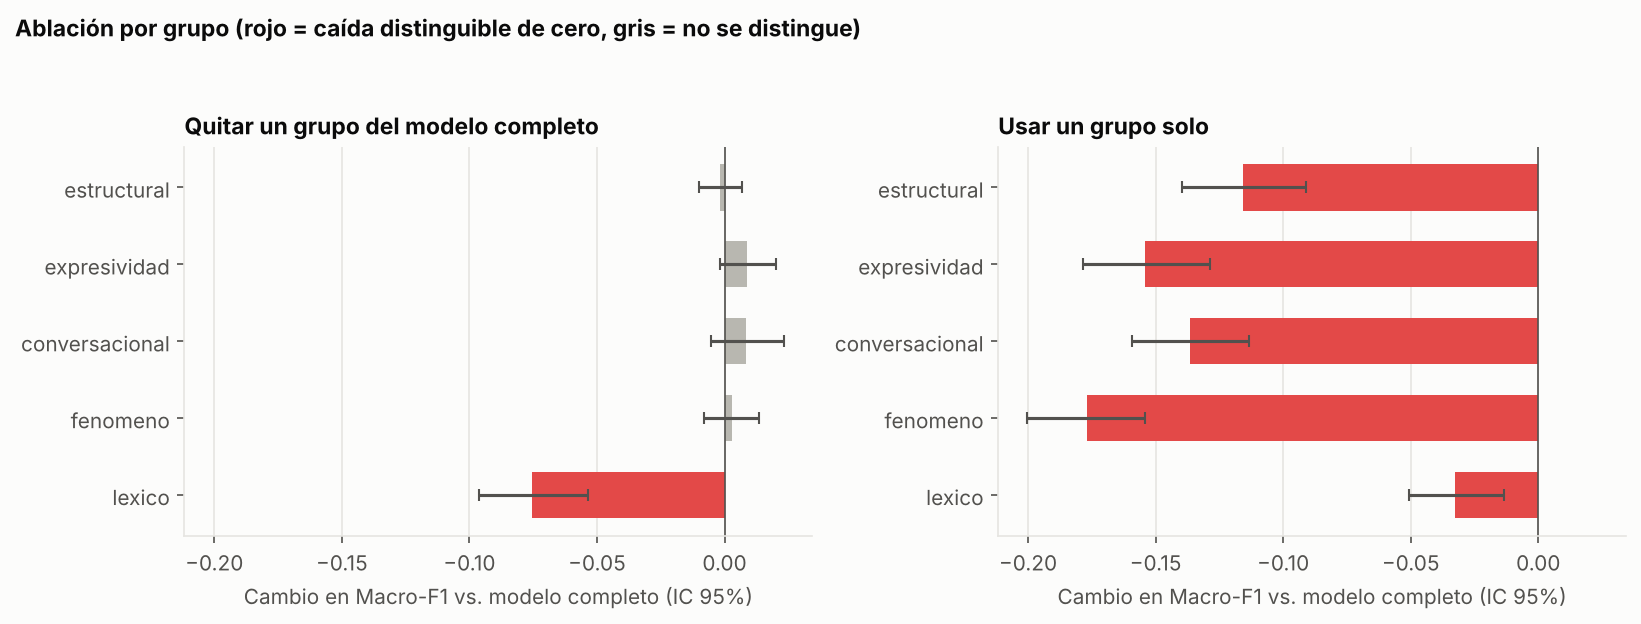

In [19]:
display(Image(filename=str(FIG / "fig05_ablacion_por_grupo.png")))

In [20]:
imp = F.importancia_permutacion(corpus)
imp.head(10)

,feature,caida_macro_f1,desv,grupo
0,n_lex_positivo,0.0800,0.0071,lexico
1,n_lex_negativo,0.0261,0.0034,lexico
2,n_negaciones,0.0128,0.0042,fenomeno
3,n_intensificadores,0.0092,0.0032,lexico
4,n_exclamaciones,0.0092,0.0033,expresividad
5,empieza_con_mencion,0.0072,0.0032,conversacional
6,n_palabras,0.0055,0.0037,estructural
7,n_interrogaciones,0.0023,0.0024,expresividad
8,n_emoticonos,0.0007,0.0002,expresividad
9,tiene_url,0.0002,0.0004,conversacional


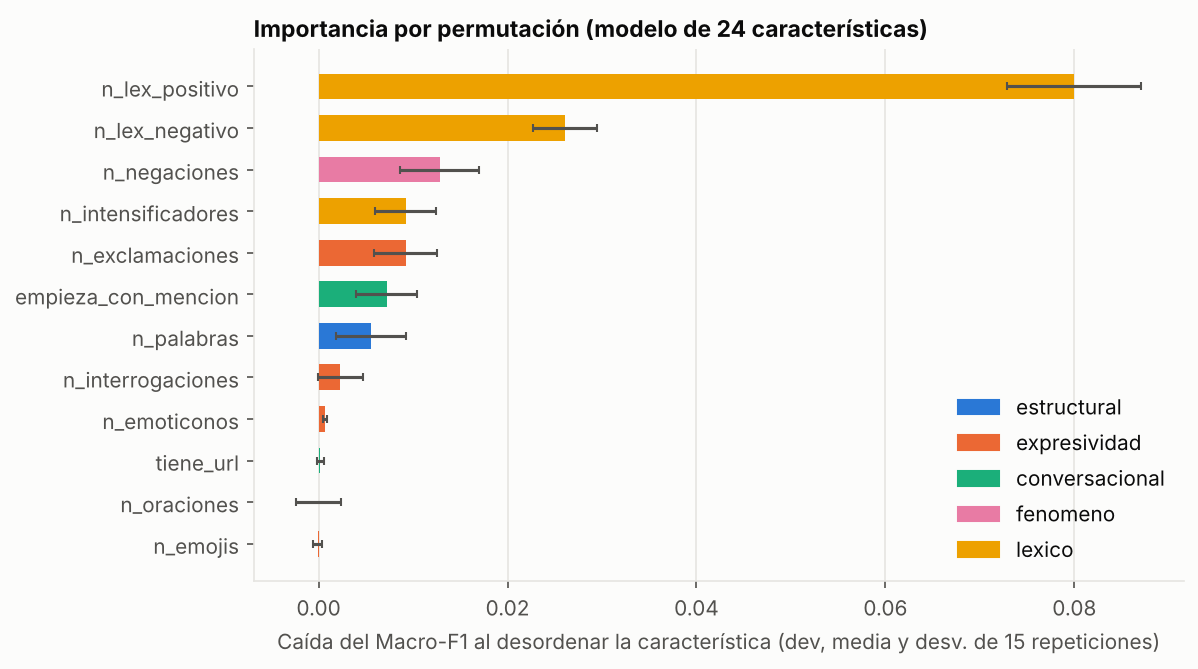

In [21]:
display(Image(filename=str(FIG / "fig06_importancia_permutacion.png")))

**Lectura.**
- Quitar el **léxico** baja el Macro-F1 en 0,075 (IC −0,096 a −0,054), y es el único grupo cuya ausencia se nota. Quitar estructural, expresividad, conversacional o fenómeno **no cambia nada distinguible**: lo que aportan lo cubren los demás grupos.
- Solo con las **3 características de léxico** se llega a 0,48, apenas 0,033 por debajo de las 24 (0,51). Cada uno de los otros grupos solo se queda entre 0,33 y 0,39.
- En la importancia por permutación, `n_lex_positivo` (caída de 0,080) y `n_lex_negativo` (0,026) dominan. Después vienen `n_negaciones` (0,013), `n_intensificadores` y `n_exclamaciones` (0,009 cada una). Varias características (emojis, emoticonos, enlaces, oraciones) no aportan nada: se pueden descartar sin pérdida.
- **Decisión:** si el catálogo se redujera, se conservarían el léxico, la negación, las exclamaciones y los intensificadores. Esto también sugiere que un **léxico validado** sería la mejora más rentable de las características.

## 9. Estabilidad frente a las perturbaciones

El proyecto planea una prueba de robustez con perturbaciones del texto: sin tildes, mayúsculas, minúsculas, letras alargadas, errores de tipeo y abreviaturas. Aquí se mide cuánto se mueve cada característica bajo esas perturbaciones, y cuánto cae el Macro-F1 de cada representación. Todos los modelos se entrenaron con texto limpio.

In [22]:
est = F.estabilidad_features(corpus)
est.set_index("feature").loc[["n_caracteres", "ratio_mayusculas", "n_palabras_mayuscula", "n_alargamientos", "n_negaciones", "n_lex_positivo", "n_lex_negativo", "n_risas", "n_exclamaciones"]]

,sin_tildes,mayusculas,minusculas,alargar_letras,tipeo,abreviaturas
feature,,,,,,
n_caracteres,0.3,0.0,0.0,85.5,0.0,69.3
ratio_mayusculas,0.0,100.0,88.7,76.2,0.0,62.2
n_palabras_mayuscula,0.0,100.0,7.7,0.0,0.0,0.4
n_alargamientos,0.0,0.0,0.0,85.4,0.2,0.0
n_negaciones,0.0,0.0,0.0,10.9,0.9,0.0
n_lex_positivo,0.0,0.0,0.0,3.3,6.2,0.0
n_lex_negativo,0.0,0.0,0.0,1.5,1.7,0.0
n_risas,0.0,0.0,0.0,0.0,1.5,0.0
n_exclamaciones,0.0,0.0,0.0,0.0,0.0,0.0


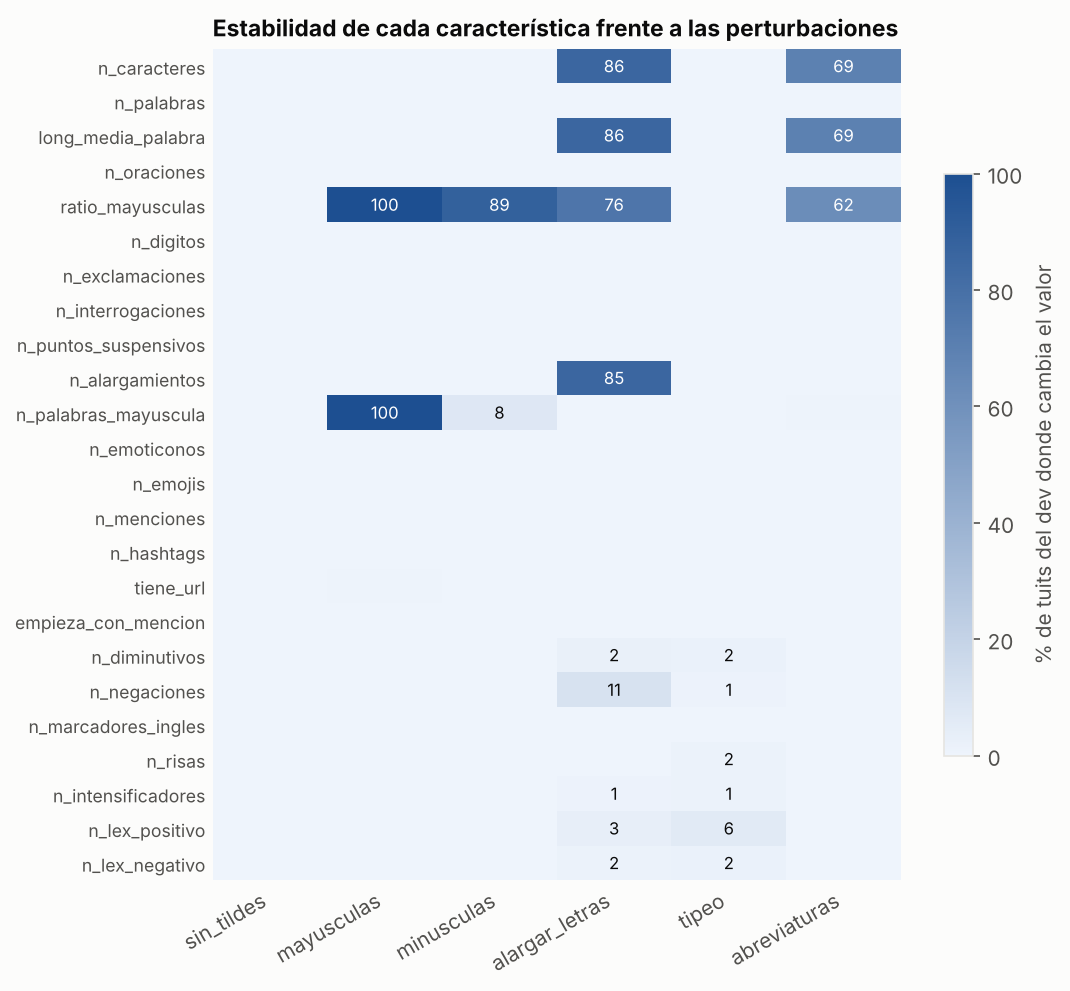

In [23]:
display(Image(filename=str(FIG / "fig07_estabilidad_features.png")))

In [24]:
rob = F.robustez_modelos(corpus)
rob.pivot(index="perturbacion", columns="representacion", values="caida")

representacion,Superficie + fenómenos + léxico (24 numéricas),TF-IDF de caracteres,TF-IDF de palabras,TF-IDF palabras + caracteres,TF-IDF palabras + numéricas
perturbacion,,,,,
abreviaturas,0.0011,-0.0014,-0.0107,-0.0049,-0.0075
alargar_letras,-0.0279,-0.0054,-0.0261,-0.0053,-0.0454
mayusculas,-0.0842,0.0001,0.0000,0.0005,-0.0473
minusculas,0.0049,0.0000,0.0000,0.0000,0.0005
sin_tildes,0.0000,-0.0093,-0.0069,-0.0072,-0.0106
tipeo,-0.0140,-0.0141,-0.0161,-0.0138,-0.0196


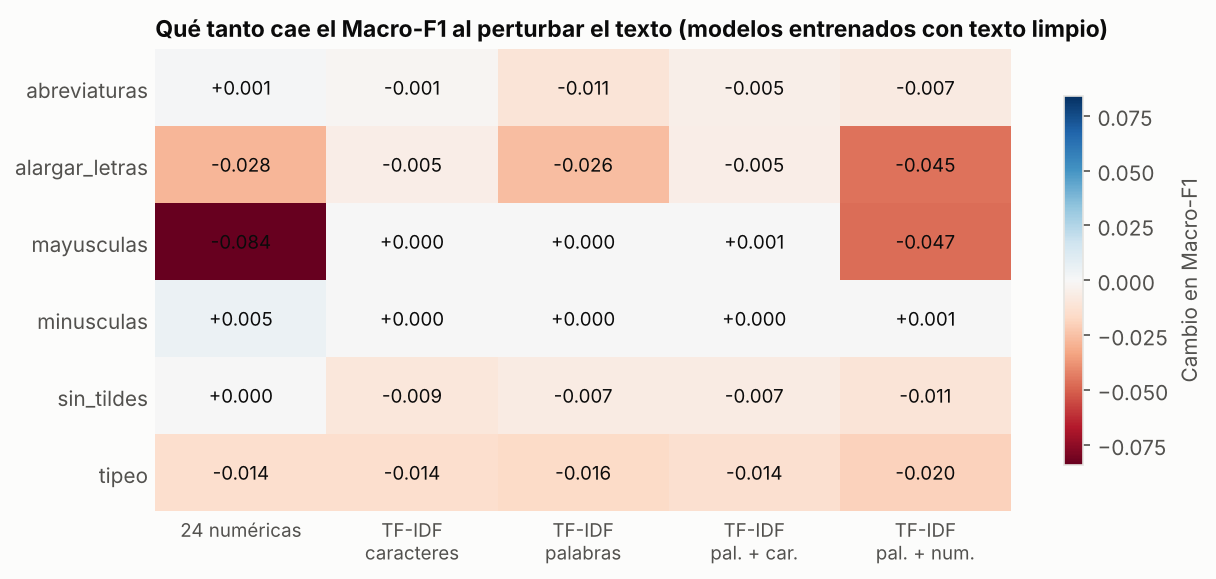

In [25]:
display(Image(filename=str(FIG / "fig08_robustez_modelos.png")))

**Lectura.**
- Las características de **mayúsculas** son las más frágiles: `ratio_mayusculas` y `n_palabras_mayuscula` cambian en el 100% de los tuits al poner todo en mayúsculas. Por eso el modelo de 24 características **cae 0,084** con esa perturbación, la mayor del análisis. TF-IDF no cambia (0,000) porque pasa todo a minúsculas.
- Las **abreviaturas** (q, x, tb, d) cambian la longitud en el 69% de los tuits, pero casi no afectan a las características de contenido ni a los modelos (entre +0,001 y −0,011).
- Las **letras alargadas** hacen caer 0,026 a TF-IDF de palabras y 0,028 al modelo numérico, mientras que TF-IDF de caracteres apenas se mueve (−0,005): los n-gramas de caracteres son más robustos.
- Los **errores de tipeo** bajan todos los modelos entre 0,014 y 0,020, y afectan sobre todo al léxico (cambia el 6% de `n_lex_positivo`), porque una palabra mal escrita deja de estar en la lista.
- **Para el experimento:** un LLM no es invariante a mayúsculas como TF-IDF. Conviene medir la caída del monoagente y del multiagente en cada perturbación, y comparar con estos números como referencia. Las perturbaciones de mayúsculas y letras alargadas son las más informativas.

## 10. Palabras con más peso por clase

In [26]:
F.terminos_por_clase(corpus).pivot(index="rank", columns="clase", values="termino")

clase,NEG,NEU,POS
rank,,,
1,triste,yo,feliz
2,no,si,gracias
3,me,hola,amo
4,feo,usuario,buena
5,peor,creo,bonito
6,odio,igual,lindo
7,extraño,por,hermoso
8,mala,normal,buen
9,ni,quiera,mejor


**Lectura.** Las palabras de NEG (*triste, feo, peor, odio*) y POS (*feliz, gracias, amo, bonito*) son afectivas y esperables. En **NEU** aparecen palabras conversacionales y de hedging (*yo, si, hola, creo, igual, normal*) y `usuario`, que viene de las menciones normalizadas: los tuits que empiezan respondiendo a alguien tienden a ser neutros. Eso confirma que parte de la señal de NEU es de estilo conversacional, y no de contenido, y que esa señal está ligada al país (sección 6).

## 11. Conclusiones y decisiones

1. **Texto del prompt:** normalización mínima (`@USUARIO`, `URL`), sin tocar mayúsculas, puntuación, emojis ni alargamientos, y sin pasar la variedad.
2. **Catálogo:** 24 características en 5 grupos, todas con definición y justificación (`docs/features/tablas/catalogo_features.csv`).
3. **Señal real:** el léxico es lo único indispensable. Con 3 características de léxico se llega a 0,48 de Macro-F1, frente a 0,51 con las 24. La negación, las exclamaciones y los intensificadores aportan algo más. Longitud, emojis, enlaces y code-switching no aportan.
4. **Agente de Percepción:** como reglas aisladas, sus banderas dicen poco (salvo la doble negación). Su valor tiene que estar en interpretar en contexto, y eso es lo que el experimento debe medir.
5. **Pisos de referencia:** clase mayoritaria (0,19) y TF-IDF (0,56 a 0,57). Entre las variantes de TF-IDF no hay diferencias distinguibles. Comparar el LLM contra ambos pisos, y reportarlo si queda por debajo de TF-IDF.
6. **Atajos:** las características conversacionales se relacionan más con el país que con el sentimiento. Usarlas con cuidado y reportar por país con contexto temporal.
7. **Robustez:** las características de mayúsculas son frágiles (el modelo numérico cae 0,084). Medir la caída del LLM bajo mayúsculas y letras alargadas, que son las perturbaciones más informativas.
8. **Redundancia:** quitar una característica de cada par redundante (`n_caracteres` con `n_palabras`, `n_menciones` con `empieza_con_mencion`) y descartar las que no aportan (emojis, emoticonos, enlaces, oraciones).
9. **Pendientes:** validar a mano las reglas (muestra de `docs/eda/tablas/muestra_validar_heuristicas.csv`) y sustituir el léxico mínimo por uno validado, que sería la mejora más rentable.